Restarted .venv01 (3.13.11) (Python 3.13.11)

In [ ]:
# ANALYSIS TCN
# SEARCH WORDS :
# YEARLY_TCN_ESTIMATION
# TESTING_MAIN_WITH_CACHE
# TCN_TRADER_DIAGNOSTICS
# TCN_FITTED_TARGET_SPACE_PERFORMANCE
# TCN_TARGET_PERFORMANCE_EXECUTED_VS_SKIPPED
# TCN_SCORE_CALIBRATION_DIAGNOSTIC
# TCN_SCORE_THRESHOLD_CALIBRATION
# TCN_SCORE_THRESHOLD_TRADER_CALIBRATION


import pandas as pd
import numpy as np
import warnings
import os, sys
import pickle

from pathlib import Path
from arch.utility.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

os.chdir("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
sys.modules.pop("srcB", None)

### NOTE :
# # COMES FROM MODELLING.ipynb
import pickle 
with open("../data/IS/outputs_by_year/outputs_by_year_01.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)


# IMPORTS FROM SRC
from srcB.market import *
from srcB.trader_testing_tcn_v2 import testing_execute_trading_strategy
from srcB.helpers import *

# READ D_BTC AND DF
from pathlib import Path
DATA_DIR = Path("../data/rawData")
YEARS = [2019, 2020, 2021]
d_btc_raw_by_year = {}
df_raw_by_year = {}
for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")

# SET INDEX TO DATETIME
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(pd.to_datetime(d_btc_raw_by_year[y]["date_time"]))
    df_raw_by_year[y] = df_raw_by_year[y].set_index(pd.to_datetime(df_raw_by_year[y]["date_time"]))


# ==================================================================================================================
# ======================================= LOAD XQ_BY_YEAR USING X_BY_YEAR ==========================================
# ==================================================================================================================

with open("../data/IS/x_by_year_fut/x_by_year.pkl", "rb") as f:
    X_by_year = pd.read_pickle(f)

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}

for y in YEARS:
    Xq_by_year[y] = {}

    Xq_by_year[y]["q1"] = X_by_year[y].loc[f"{y}-01-01" : f"{y}-03-31 23:59:59"].copy()

    Xq_by_year[y]["q2"] = X_by_year[y].loc[f"{y}-04-01" : f"{y}-06-30 23:59:59"].copy()

    Xq_by_year[y]["q3"] = X_by_year[y].loc[f"{y}-07-01" : f"{y}-09-30 23:59:59"].copy()

    Xq_by_year[y]["q4"] = X_by_year[y].loc[f"{y}-10-01" : f"{y}-12-31 23:59:59"].copy()


# ==================================================================================================================
# ======================================= MFIV SCALING =============================================================
# ================== CONVERT ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE ===============================
# ==================================================================================================================

MFIVS = list(range(2, 577))
for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= H / 8760.0


# ==================================================================================================================
# ============================================= BORROW RFR COLUMN  =================================================
# ==================================================================================================================
import pickle
with open ("../data/IS/ready_data/d_btc_by_year_all.pkl", "rb") as f :
    d_btc_by_year = pickle.load(f)

YEARS = [2019, 2020, 2021]
for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(d_btc_raw_by_year[y].index, method="ffill")

# =============================================================================================================
# ======================================= CHECKPOINT 1. RUN UNTIL HERE ========================================
# =============================================================================================================

In [ ]:
# # =============================== LOAD OPTIMAL PARAMETERS IN hyperparam_tuning.py ==================================
expand_index = "_e01"
with open(f"../data/IS/hyperparameters/tcn_best_params{expand_index}.pkl", "rb") as f:
    best_tcn_params = pickle.load(f)

FORWARD_HOURS = 24

In [ ]:
# # ======================================= YEARLY_TCN_ESTIMATION  ===================================================
# # ==================================================================================================================
sys.modules.pop("srcB.tcn_model_mfiv", None)
from srcB.tcn_model_mfiv import *

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]
tcn_bundle_by_year = {}
tcn_targets_by_year = {}
tcn_output_by_year = {}

for y in YEARS:
    X_df = pd.concat([
        Xq_by_year[y][q]
        for q in QUARTERS
    ]).sort_index().copy()

    garch_df = pd.concat([
        outputs_by_year[y][q]["garch"]
        for q in QUARTERS
    ]).sort_index()

    X_df["garch"] = garch_df.reindex(X_df.index)

    tcn_output, tcn_bundle, tcn_targets = tcn_mfiv(
        X_df=X_df,
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        sequence_length=168,
        forward_hours=FORWARD_HOURS,
        delta_target=0.20,
        channels=best_tcn_params["channels"],
        kernel_size=best_tcn_params["kernel_size"],
        dropout=best_tcn_params["dropout"],
        epochs=best_tcn_params["epochs_by_year"][y],
        batch_size=best_tcn_params["batch_size"],
        learning_rate=best_tcn_params["learning_rate"],
        weight_decay=best_tcn_params["weight_decay"]
    )
    tcn_output_by_year[y] = tcn_output
    tcn_bundle_by_year[y] = tcn_bundle
    tcn_targets_by_year[y] = tcn_targets

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        tcn_q = tcn_output.reindex(q_index)
        outputs_by_year[y][q] = pd.concat( [outputs_by_year[y][q], tcn_q], axis=1 )

In [ ]:
os.makedirs("../data/IS/TCN", exist_ok = True)
import pickle
with open("../data/IS/TCN/tcn_bundle_by_year.pkl", "wb") as f:
    pickle.dump(tcn_bundle_by_year, f)

print("TCN bundles saved:", list(tcn_bundle_by_year.keys()))

TCN bundles saved: [2019, 2020, 2021]


In [ ]:
# # ==================================================================================================================
# SAVE THIS OUTPUTS
with open("../data/IS/outputs_by_year/outputs_by_year_04.pkl", "wb") as f:
    pickle.dump(outputs_by_year, f)
## ==================================================================================================================

In [ ]:
# # =============================================================================================================
# # ======================================= CHECKPOINT 2. RUN FROM HERE ==================================================================================================
# # =============================================================================================================

# import pickle
# with open("../data/IS/outputs_by_year/outputs_by_year_04.pkl", "rb") as f:
#     outputs_by_year = pickle.load(f)

# # IMPORTS FROM SRC
from srcB.market import *
from srcB.trader_testing_tcn_v2 import testing_execute_trading_strategy
from srcB.helpers import *

In [ ]:
# ==================================================================================================================
# ======================================= PREPARE TRADER INPUT ======================================================
# ==================================================================================================================

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["rv"] = Xq_by_year[y][q]["rv"].reindex(
            outputs_by_year[y][q].index
        )
        outputs_by_year[y][q]["MFIV_24"] = Xq_by_year[y][q]["MFIV_24"].reindex(
            outputs_by_year[y][q].index
        )

# ==================================================================================================================
# ======================================= CACHE FOR WARMUP ==========================================================
# ==================================================================================================================
CACHE_YEARS = [2019, 2020, 2021]
RUN_BY = "year"
if RUN_BY == "year":
    trader_cache = {
        y: pd.concat(
            [
                outputs_by_year[yy][q]
                for yy in CACHE_YEARS
                if yy <= y
                for q in QUARTERS
            ]
        ).sort_index()
        for y in CACHE_YEARS
    }

elif RUN_BY == "quarter":
    trader_cache = {
        (y, q): pd.concat(
            [
                outputs_by_year[yy][qq]
                for yy in CACHE_YEARS
                for qq in QUARTERS
                if (
                    yy < y
                    or (yy == y and QUARTERS.index(qq) <= QUARTERS.index(q))
                )
            ]
        ).sort_index()
        for y in CACHE_YEARS
        for q in QUARTERS
    }
if RUN_BY == "year":
    PERIODS = YEARS
else:
    PERIODS = [(y, q) for y in YEARS for q in QUARTERS]

In [ ]:
# ==================================================================================================================
# ======================================= TESTING_MAIN_WITH_CACHE  ==========================================================
# ==================================================================================================================
# sys.modules.pop("srcB", None)

sys.modules.pop("srcB.trader_testing_tcn_v2", None)
from srcB.trader_testing_tcn_v2 import testing_execute_trading_strategy
YEARS = [2019, 2020, 2021]
MODELS = [
    "tcn_mfiv"
]
RUN_BY = "year"
strategy_results = {}
for YEAR in YEARS:
    for MODEL in MODELS:
        market = Market(
            option_df=df_raw_by_year[YEAR],
            time_df=d_btc_raw_by_year[YEAR],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )
        greek_tests = []
        yearly_snapshots = []
        if RUN_BY == "year":
            periods = [None]
        else:
            periods = ["q1", "q2", "q3", "q4"]
            
        for q in periods:
            snapshots, greek_tests_q = testing_execute_trading_strategy(
                bt_year=YEAR,
                bt_quarter=q,
                model=MODEL,
                outputs_by_year=outputs_by_year,
                market=market,
                trader_cache=trader_cache,
                run_by=RUN_BY,
                quantity=10,
                forward_hours=FORWARD_HOURS
            )

            greek_tests.extend(greek_tests_q)
            yearly_snapshots.extend(snapshots)
        history_key = f"{MODEL}_{str(YEAR)[2:]}"
        equity_curve = market.get_equity_history()
        strategy_results[history_key] = {
            "equity_curve": equity_curve,
            "snapshots": yearly_snapshots,
            "greek_tests": greek_tests,
            "orders": list(market.orders),
            "transactions": list(market.transactions),
            "final_cash": market.cash,
            "required_margin": market.get_total_required_margin(),
            "free_liquidity": market.get_free_liquidity(),
        }
print(YEAR, MODEL)

2021 tcn_mfiv


In [ ]:
# ==================================================================================================================
# ============================================= SAVE DICT  ========================================================
# ==================================================================================================================
import sys, os
os.makedirs("../data/data_strategy_results", exist_ok = True)
import pickle 
with open("../data/data_strategy_results/strategy_results.pkl", "wb") as f:
    pickle.dump(strategy_results, f)

In [ ]:
## ==================================================================================================================
## ============================================= SHARPEE  ===========================================================
## ==================================================================================================================
YEARS = [2019, 2020, 2021]
MODELS = ["tcn_mfiv"]
rows = []

for y in YEARS:
    for model in MODELS:

        history_key = f"{model}_{str(y)[2:]}"
        snapshots = strategy_results[history_key]["snapshots"]

        equity = pd.Series( [s["equity"] for s in snapshots], index=[s["time"] for s in snapshots] )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({ "year": y, "model": model, "sharpe": sharpe })

sharpe_table = pd.DataFrame(rows)

print(sharpe_table)

   year     model    sharpe
0  2019  tcn_mfiv  0.481708
1  2020  tcn_mfiv  0.646442
2  2021  tcn_mfiv  1.148113


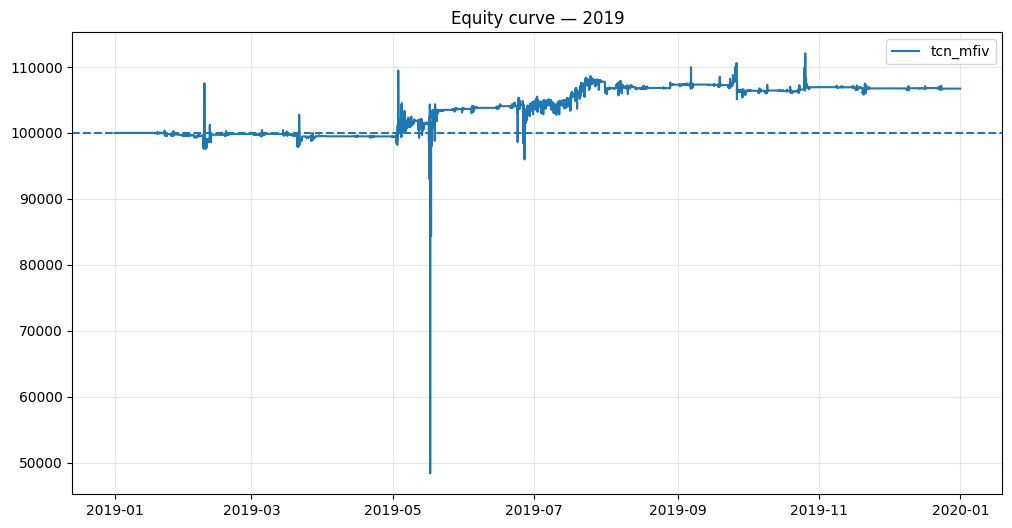

In [ ]:
# ============================================= PLOT EQUITY  =======================================================
# ==================================================================================================================
import matplotlib.pyplot as plt
# MODELS = ["garch", "garch_mfiv", "garch_n_mfiv", "garch_mfiv_avg", "regime_switching_mfiv"]
MODELS = ["tcn_mfiv"]
PLOT_YEAR = 2019
plt.figure(figsize=(12, 6))
for MODEL in MODELS:
    plot_key = f"{MODEL}_{str(PLOT_YEAR)[2:]}"
    result = strategy_results[plot_key]
    eq = pd.DataFrame(result["snapshots"]).drop_duplicates("time").sort_values("time")
    plt.plot(eq["time"], eq["equity"], label=MODEL)
plt.axhline(100_000, linestyle="--")
plt.title(f"Equity curve — {PLOT_YEAR}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# # ============================================= PHASE 2 =====================================================
# # ======================================= DIAGNOSTICS FOR TCN ===============================================
# # ===========================================================================================================
## 1=============================================================================================================
## ============================== TCN FITTED TARGET-SPACE PERFORMANCE ==========================================
## =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort = False).dropna()
    realized = pd.Series(0.0, index=test.index)
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["tcn_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]
    sharpe = realized.mean() / realized.std()
    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })
target_sharpe = pd.DataFrame(rows)
print(target_sharpe)

   year     n  mean_target  target_sharpe  profitable
0  2019  2182     0.000113       0.057916    0.173694
1  2020  4058     0.000303       0.110984    0.329719
2  2021  4943     0.000213       0.094861    0.478657


In [ ]:
# 2=========================== REQUIRES STRATEGY_RESULTS =======================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()

    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(strategy_results[f"tcn_mfiv_{str(y)[2:]}"]["greek_tests"])
    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")
    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["tcn_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)

print(execution_check)

   year  signals  successful_entries  entries_with_target  target_coverage  \
0  2019      722                 206                  124         0.601942   
1  2020     2263                 350                  276         0.788571   
2  2021     3951                 523                  405         0.774379   

   action_match  all_sharpe  executed_sharpe  skipped_sharpe  
0           1.0    0.100980         0.118907        0.098193  
1           1.0    0.149335         0.062524        0.158021  
2           1.0    0.106220         0.080846        0.109732  


In [ ]:
# 3========Are higher-score bins better? ==============
# ============================= TCN_SCORE_CALIBRATION_DIAGNOSTIC ========================================
# =============================================================================================================
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
        
    test["score_bin"] = pd.qcut(
        test["tcn_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("tcn_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))

 year  score_bin   n  mean_score  mean_target    sharpe  profitable
 2019          0 145    0.000045     0.000181  0.057634    0.517241
 2019          1 144    0.000148     0.000142  0.055746    0.520833
 2019          2 144    0.000285     0.000006  0.002022    0.479167
 2019          3 144    0.000447     0.000395  0.107474    0.548611
 2019          4 145    0.000756     0.000972  0.234302    0.558621
 2020          0 453    0.000050    -0.000065 -0.039544    0.547461
 2020          1 452    0.000180    -0.000026 -0.014118    0.564159
 2020          2 453    0.000395     0.000157  0.070125    0.571744
 2020          3 452    0.000720     0.000530  0.201371    0.639381
 2020          4 453    0.002860     0.002117  0.316377    0.633554
 2021          0 791    0.000050    -0.000045 -0.020215    0.553729
 2021          1 790    0.000109     0.000111  0.049976    0.588608
 2021          2 790    0.000215     0.000020  0.008292    0.582278
 2021          3 790    0.000351     0.000254  0

In [ ]:
# #4 ===If I only retain signals with tcn_best_score >= threshold, does target-space performance improve? ========
# # ================================= TCN_SCORE_THRESHOLD_CALIBRATION ===========================================
# # =============================================================================================================

tests = {}

for y in YEARS:

    x = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["tcn_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["tcn_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x


scores_all = pd.concat([tests[y]["tcn_best_score"] for y in YEARS])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["tcn_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)

print(threshold_check.to_string(index=False))

 quantile    threshold  year    n  mean_target   sharpe
     0.00 2.477609e-07  2019  722     0.000340 0.100980
     0.00 2.477609e-07  2020 2263     0.000543 0.149335
     0.00 2.477609e-07  2021 3951     0.000267 0.106220
     0.20 7.646474e-05  2019  601     0.000364 0.107084
     0.20 7.646474e-05  2020 1924     0.000651 0.168164
     0.20 7.646474e-05  2021 3024     0.000353 0.137656
     0.40 1.896018e-04  2019  451     0.000436 0.120139
     0.40 1.896018e-04  2020 1542     0.000847 0.200105
     0.40 1.896018e-04  2021 2169     0.000478 0.178476
     0.50 2.545449e-04  2019  385     0.000548 0.147580
     0.50 2.545449e-04  2020 1396     0.000925 0.211197
     0.50 2.545449e-04  2021 1687     0.000610 0.222155
     0.60 3.376402e-04  2019  314     0.000683 0.178860
     0.60 3.376402e-04  2020 1234     0.001031 0.225105
     0.60 3.376402e-04  2021 1227     0.000723 0.253864
     0.70 4.405144e-04  2019  214     0.001036 0.258848
     0.70 4.405144e-04  2020 1049     0.001199 0

In [ ]:
# 5===== Does the threshold improvement survive the actual sequential trader? =====
# ================================ TCN_SCORE_THRESHOLD_TRADER_CALIBRATION =====================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn_v2", None)
from srcB.trader_testing_tcn_v2 import testing_execute_trading_strategy

THRESHOLDS = [
    0.0,
    float(scores_all.quantile(.70)),
    float(scores_all.quantile(.80)),
    float(scores_all.quantile(.85)),
    float(scores_all.quantile(.90))
]
rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold,
            forward_hours=FORWARD_HOURS
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)
        final_equity = equity.iloc[-1]
        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": sum(t["action"] in ("buy_to_open", "sell_to_open") for t in market.transactions) // 2,
            "sharpe": sharpe,
            "final_equity" : final_equity
        })

threshold_trader_check = pd.DataFrame(rows)

print(threshold_trader_check.to_string(index=False))

 threshold  year  trades   sharpe  final_equity
  0.000000  2019     206 0.481708 106719.207080
  0.000000  2020     350 0.646442 109087.195508
  0.000000  2021     523 1.148113 127744.500500
  0.000441  2019      81 0.461615 102538.443064
  0.000441  2020     217 0.545682 116329.546262
  0.000441  2021     264 0.990348 125037.675015
  0.000584  2019      55 0.465329 103833.318967
  0.000584  2020     195 0.248154 100450.508768
  0.000584  2021     185 0.854343 139078.620720
  0.000693  2019      36 0.261665 102644.937704
  0.000693  2020     181 0.309460 104829.282761
  0.000693  2021     112 0.960325 143784.736271
  0.000914  2019      18 0.412825 102272.600085
  0.000914  2020     155 0.269058 103416.547435
  0.000914  2021      55 0.637026 121283.869307


In [ ]:
DIAGNOSTICS_DIR = "../data/IS/diagnostics"
os.makedirs(DIAGNOSTICS_DIR, exist_ok=True)

with open(f"{DIAGNOSTICS_DIR}/tcn_targets_by_year.pkl", "wb") as f:
    pickle.dump(tcn_targets_by_year, f)

with open(f"{DIAGNOSTICS_DIR}/tcn_output_by_year.pkl", "wb") as f:
    pickle.dump(tcn_output_by_year, f)